In [107]:
import numpy as np
import matplotlib.pyplot as plt

In [108]:
def newton_raphson_2d(F, J, x0, tol=0.5e-6, max_iter=100):
  """
  Newton-Raphson method for a system of two nonlinear equiations.

  Parameters:
    F (function): A function that returns the vector of equations.
    J (function): A function that returns the Jacobian matrix.
    x0 (array-like): Initial Guess [x, y].
    tol (float): Tolerance for stopping criterion.
    max_iter (int): Maximum number of iterations.

  Returns:
    x (numpy array): Approximated Root [x, y].
    error_table (list): Error and root approximations at each iteration.
  """
  x = np.array(x0, dtype=float)
  error_table = []
  for i in range(max_iter):
    F_val = np.array(F(x))
    J_val = np.array(J(x))
    # Solve J*delta = -F
    delta = np.linalg.solve(J_val, -F_val)
    x_next = x + delta    # NR formula
    error = np.linalg.norm(delta)
    error_table.append((i+1, x_next[0], x_next[1], error))
    # Check for convergence
    if error < tol:
      return x_next, error_table
    x = x_next
  raise RuntimeError("Maximum iterations exceeded without convergence.")

In [109]:
# Define the system of equations
def F_example(x):
  return [
    # x[0]**2+x[1]**2-4,     # f1(x, y) = x^2+y^2-4
    # np.exp(x[0])+x[1]-1    # f2(x, y) = e^x+y-1
    x[0]**2+x[1]**2-x[1]-5,
    -np.exp(-x[0])+x[1]-1
  ]

In [110]:
# Define the Jacobian
def J_example(x):
  return [
      # [2*x[0], 2*x[1]],    # Partial derivatives of f1
      # [np.exp(x[0]), 1]    # Partial derivatives of f2
      [2*x[0], 2*x[1]-1],
      [np.exp(-x[0]), 1]
  ]

In [111]:
# Initial guess for the system of equations
x0_example = [2, 2]

In [112]:
# Find the root and generate the error table
root_2d, error_table_2d = newton_raphson_2d(F_example, J_example, x0_example)

In [113]:
# Print the results
print("Iteration\tX\t\tY\t\tError")
for row in error_table_2d:
  print(f"{row[0]}\t\t{row[1]:.6f}\t{row[2]:.6f}\t{row[3]:.6e}")

Iteration	X		Y		Error
1		2.443516	1.075312	1.025551e+00
2		2.221035	1.106178	2.246117e-01
3		2.208679	1.109837	1.288634e-02
4		2.208638	1.109850	4.309178e-05
5		2.208638	1.109850	4.818423e-10


In [114]:
print(f"\nRoot: {root_2d}")


Root: [2.20863823 1.10985014]


In [115]:
# Plot the convergence
iterations = [row[0] for row in error_table_2d]
errors = [row[3] for row in error_table_2d]

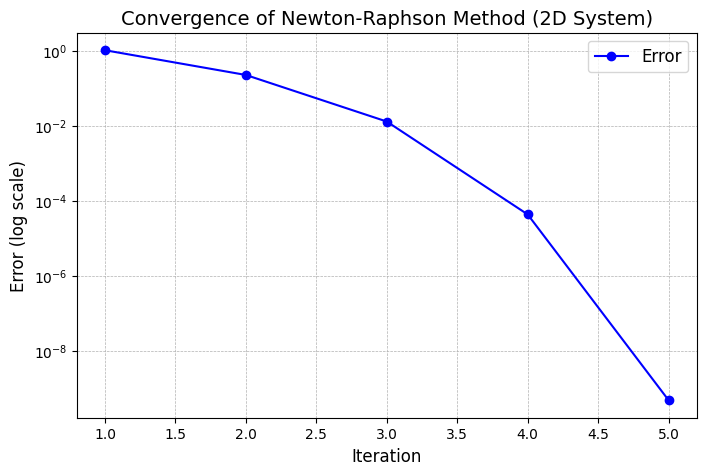

In [116]:
plt.figure(figsize=(8, 5))
plt.semilogy(iterations, errors, marker='o', linestyle='-', color='b', label='Error')
plt.title('Convergence of Newton-Raphson Method (2D System)', fontsize=14)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Error (log scale)', fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend(fontsize=12)
plt.show()